<a href="https://colab.research.google.com/github/komazawa-deep-learning/komazawa-deep-learning.github.io/blob/master/2026notebooks/2026_1127pe_reversal.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 逆唱で見る長さの外挿: 正弦波 PE と RoPE の違い

ひらがなの文字列を逆から言う課題 (逆唱; 例: `さくらもち` → `ちもらくさ`) を Transformer に学習させる。

* **3〜5 文字で学習** し，**6〜8 文字でテスト** する (学習した長さより長い入力への汎化 = 長さの外挿)。
* PE は 3 通り: PE なし (`none`)，正弦波 PE (`sinusoidal`，絶対位置)，RoPE (`rope`，相対位置)。

逆唱は，出力の $i$ 文字目が入力の「後ろから $i$ 番目」の文字で決まる。したがって **位置の情報がなければ原理的に解けない**。
また，入力が 6 文字になっても「後ろから数えて写す」という操作は学習時と同じなので，**位置の外挿だけ** を問う課題になっている
(足し算の 2 桁 → 3 桁との違いは `pe_addition.ipynb` の 8 節を参照)。

学習に使う文字列はランダムに並べたひらがななので，ほとんどが **実在しない語 (非語)** である。
実在語のリストを使うときは `tk.pairs_from_words(語のリスト)` でデータを作れる。

## 1. 準備

In [2]:
import os, sys, subprocess
IN_COLAB = 'google.colab' in sys.modules

REPO_URL = 'https://github.com/ShinAsakawa/CDP_ja.git'   # 2 ファイルを置いたリポジトリ
NEEDED = ['pe_transformer.py', 'pe_tasks.py']

def find_dir():
    for d in ['.', 'CDP_ja']:
        if all(os.path.exists(os.path.join(d, f)) for f in NEEDED):
            return d
    return None

WORK_DIR = find_dir()
if WORK_DIR is None and IN_COLAB:
    if not os.path.exists('CDP_ja'):
        subprocess.run(['git', 'clone', '-q', REPO_URL], check=False)
    WORK_DIR = find_dir()
if WORK_DIR is None and IN_COLAB:
    from google.colab import files
    print('pe_transformer.py と pe_tasks.py をアップロードしてください')
    files.upload()
    WORK_DIR = find_dir()
assert WORK_DIR is not None, f'{NEEDED} が見つからない。このノートブックと同じフォルダに置くこと'
sys.path.insert(0, os.path.abspath(WORK_DIR))

# 日本語フォント
try:
    import japanize_matplotlib
except Exception:
    try:
        import matplotlib_fontja
    except ImportError:
        subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'matplotlib-fontja'], check=False)
        import matplotlib_fontja

%config InlineBackend.figure_format = 'retina'
import random, time
import numpy as np
import torch
import matplotlib.pyplot as plt
from IPython.display import HTML, display
import pe_transformer as pt
import pe_tasks as tk

FIG_DIR = 'figures'          # 図をファイルにも保存する (スライド・配布資料用)
os.makedirs(FIG_DIR, exist_ok=True)

# デバイス: cuda (Colab GPU) > mps (Apple Silicon) > cpu
# このモデルは小さいので，mps より cpu の方が速いことがある。その場合は下の行を有効にする
DEVICE = pt.get_device()
# DEVICE = torch.device('cpu')
print('Colab:', IN_COLAB, '| device:', DEVICE, '| torch:', torch.__version__)

Colab: True | device: cuda | torch: 2.14.1+cu130


In [3]:
def show_table(header, rows, caption=''):
    """簡単な HTML 表を表示する"""
    h = ''.join(f'<th style="padding:2px 10px">{x}</th>' for x in header)
    b = ''.join('<tr>' + ''.join(f'<td style="padding:2px 10px;text-align:center">{x}</td>' for x in r) + '</tr>'
                for r in rows)
    display(HTML(f'<b>{caption}</b><table><tr>{h}</tr>{b}</table>'))

COLORS = {'none': 'tab:gray', 'sinusoidal': 'tab:blue', 'rope': 'tab:red'}
LABELS = {'none': 'PE なし', 'sinusoidal': '正弦波 PE', 'rope': 'RoPE'}

## 2. データ

In [4]:
TRAIN_LENGTHS = range(3, 6)        # 3〜5 文字で学習
TEST_LENGTHS = [6, 7, 8]            # 6〜8 文字でテスト
TRAIN_MAX = max(TRAIN_LENGTHS)

vocab = tk.make_vocab(tk.HIRAGANA)
train = tk.reversal_pairs(TRAIN_LENGTHS, 8000, seed=0)
seen = {s for s, _ in train}

def sample(pairs, n, seed):
    pairs = list(pairs); random.Random(seed).shuffle(pairs); return pairs[:n]

tests = {f'{L}': sample([p for p in tk.reversal_pairs([L], 600, seed=50 + L) if p[0] not in seen], 300, L)
         for L in TRAIN_LENGTHS}                                  # 学習範囲内 (未学習の文字列)
tests.update({f'{L}': sample(tk.reversal_pairs([L], 300, seed=50 + L), 300, L) for L in TEST_LENGTHS})
LENGTHS = list(TRAIN_LENGTHS) + TEST_LENGTHS

print('学習:', len(train), '例 (3〜5 文字) | 語彙数:', len(vocab))
print('学習データの例:', sample(train, 5, 0))
print('テスト:', {k: len(v) for k, v in tests.items()})

学習: 8000 例 (3〜5 文字) | 語彙数: 50
学習データの例: [('てにををに', 'にををにて'), ('ふらみう', 'うみらふ'), ('へめうと', 'とうめへ'), ('あらこち', 'ちこらあ'), ('すひみ', 'みひす')]
テスト: {'3': 300, '4': 300, '5': 300, '6': 300, '7': 300, '8': 300}


## 3. 学習

3 条件 × 3 シード。CPU で 1 条件あたり 1 分弱，合計 7〜8 分程度 (Colab の GPU ならもっと速い)。
時間を短くしたいときは `SEEDS = [0]` にする。

In [5]:
cfg = pt.Config(model_dim=64, num_heads=4, num_layers=2, ff_dim=128,
                epochs=15, batch_size=128, lr=2e-3, lr_schedule='cosine', eval_every=15)
CONDITIONS = ['none', 'sinusoidal', 'rope']
SEEDS = [0, 1, 2]

models = {}
for pe in CONDITIONS:
    for seed in SEEDS:
        cfg.seed = seed
        m, h = tk.train_task(cfg, train, vocab, pe, pe, device=DEVICE)
        models[(pe, seed)] = m
        print(f'{LABELS[pe]:>8s} seed={seed}: {h["time"]:.0f} 秒')

   PE なし seed=0: 20 秒
   PE なし seed=1: 17 秒
   PE なし seed=2: 17 秒
  正弦波 PE seed=0: 17 秒
  正弦波 PE seed=1: 18 秒
  正弦波 PE seed=2: 18 秒
    RoPE seed=0: 22 秒
    RoPE seed=1: 22 秒
    RoPE seed=2: 22 秒


## 4. 長さごとの正解率

* **完全一致率**: 逆唱が 1 文字も違わずに正しい割合
* **文字一致率**: 位置ごとに文字が合っている割合 (部分的にどこまで合っているか)

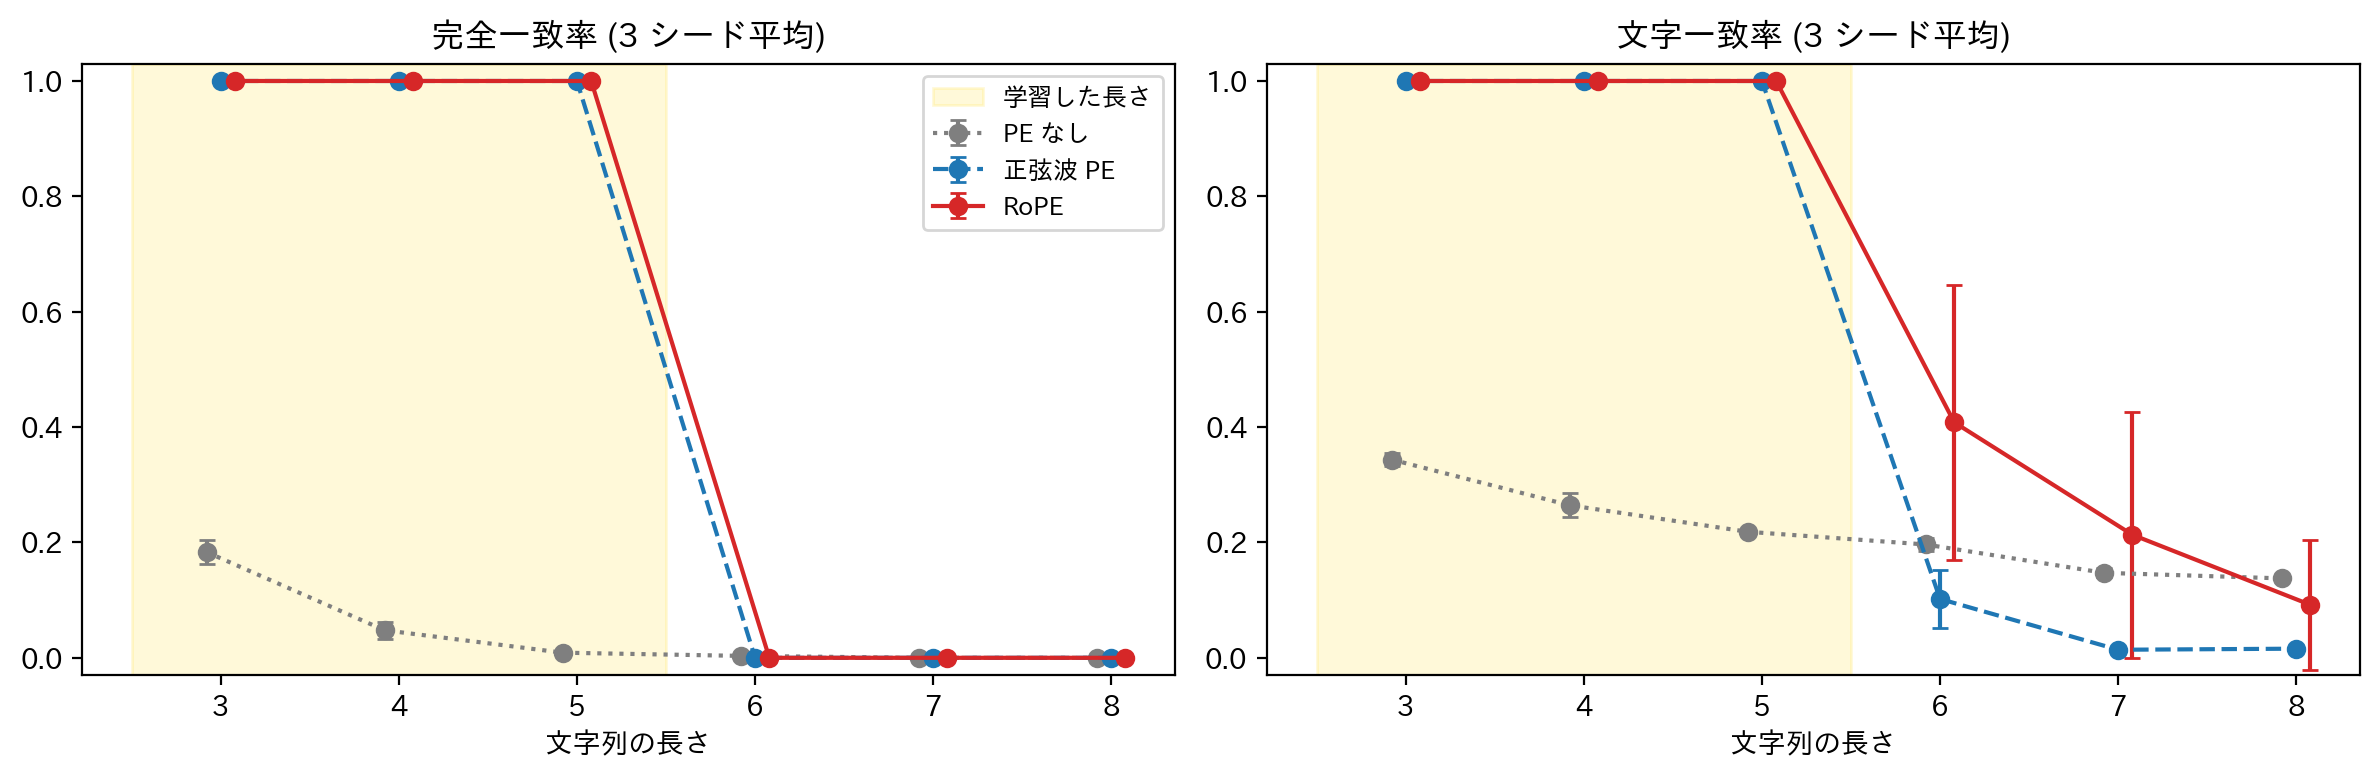

条件,3 文字,4 文字,5 文字,6 文字,7 文字,8 文字
PE なし,0.34,0.26,0.22,0.20,0.15,0.14
正弦波 PE,1.00,1.00,1.00,0.10,0.01,0.02
RoPE,1.00,1.00,1.00,0.41,0.21,0.09


In [6]:
res = {(pe, s, L): tk.accuracy(m, tests[str(L)], vocab, DEVICE)
       for (pe, s), m in models.items() for L in LENGTHS}

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, key, title in zip(axes, ['exact', 'char'], ['完全一致率', '文字一致率']):
    for pe in CONDITIONS:
        Y = np.array([[res[(pe, s, L)][key] for L in LENGTHS] for s in SEEDS])
        off = {'none': -0.08, 'sinusoidal': 0.0, 'rope': 0.08}[pe]       # 重なって見えなくならないよう少しずらす
        ls = {'none': ':', 'sinusoidal': '--', 'rope': '-'}[pe]
        ax.errorbar(np.array(LENGTHS) + off, Y.mean(0), yerr=Y.std(0), marker='o', ls=ls, capsize=3,
                    color=COLORS[pe], label=LABELS[pe])
    ax.axvspan(min(TRAIN_LENGTHS) - 0.5, TRAIN_MAX + 0.5, color='gold', alpha=0.15, label='学習した長さ')
    ax.set_xlabel('文字列の長さ'); ax.set_ylim(-0.03, 1.03); ax.set_title(title + ' (3 シード平均)')
axes[0].legend(fontsize=9)
plt.tight_layout(); plt.savefig(f'{FIG_DIR}/rev_accuracy_by_length.png', dpi=200); plt.show()

show_table(['条件'] + [f'{L} 文字' for L in LENGTHS],
           [[LABELS[pe]] + [f'{np.mean([res[(pe, s, L)]["char"] for s in SEEDS]):.2f}' for L in LENGTHS]
            for pe in CONDITIONS],
           '文字一致率 (3 シード平均)。3〜5 文字が学習範囲')

## 5. 生成例を見る

同じ入力に対して，各条件のモデル (シード 0) が何を出力したか。

In [7]:
def mark(p, t):
    return ''.join(c if j < len(t) and c == t[j] else f'<b style="color:red">{c}</b>' for j, c in enumerate(p)) \
        + ('<span style="color:red">＿</span>' * max(0, len(t) - len(p)))

rows = []
for L in [5, 6, 7]:
    for s, t in tests[str(L)][:4]:
        preds = [tk.accuracy(models[(pe, 0)], [(s, t)], vocab, DEVICE)['preds'][0] for pe in CONDITIONS]
        rows.append([f'{L}', s, t] + [mark(p, t) for p in preds])
show_table(['長さ', '入力', '正解'] + [LABELS[pe] for pe in CONDITIONS], rows,
           '生成例 (赤字は誤り，＿ は足りない文字)')

長さ,入力,正解,PE なし,正弦波 PE,RoPE
5,くみむゆえ,えゆむみく,むえくゆみ,えゆむみく,えゆむみく
5,なくめひこ,こひめくな,ひくこめな,こひめくな,こひめくな
5,ちりもまち,ちまもりち,ちもちりま,ちまもりち,ちまもりち
5,はたんもほ,ほもんたは,もほたはん,ほもんたは,ほもんたは
6,きみうもねわ,わねもうみき,きわみもうね,ねもうみき＿,わねうみみ＿
6,ゆせいゆせえ,えせゆいせゆ,ゆせえいゆいせ,えゆいせゆ＿,えせゆせゆ＿
6,けこわめたこ,こためわこけ,こけこたわめ,ためわわけ＿,こためわこ＿
6,そちにたひな,なひたにちそ,たそになひち,ひひたにち＿,なひたにち＿
7,くはししのちき,きちのししはく,しちはのきくし,のししはく＿＿,きちししく＿＿
7,るほへいのえり,りえのいへほる,えるほいりのた,のいへほる＿＿,りえのいる＿＿


## 6. 誤り方を分類する

学習した長さ (5 文字) を超えたときの誤りを，次の 4 種類に分ける。

| 分類 | 意味 | 例 (入力 `あきむさくつ`) |
|---|---|---|
| 正解 | | `つくさむきあ` |
| 先頭だけ逆順 | 入力の **先頭 5 文字** を逆にしたもの。学習で見た位置 (1〜5 番目) の範囲だけで処理している | `くさむきあ` |
| 末尾から開始 | 1 文字目 (入力の最後の文字) は正しいが，全体は誤り | `つくさきあ` |
| その他 | 上記以外 | |

条件,正解,先頭だけ逆順,末尾から開始,その他
PE なし,0.00,0.00,0.24,0.76
正弦波 PE,0.00,0.74,0.07,0.18
RoPE,0.00,0.15,0.35,0.51


条件,正解,先頭だけ逆順,末尾から開始,その他
PE なし,0.00,0.00,0.18,0.82
正弦波 PE,0.00,0.68,0.01,0.31
RoPE,0.00,0.00,0.35,0.65


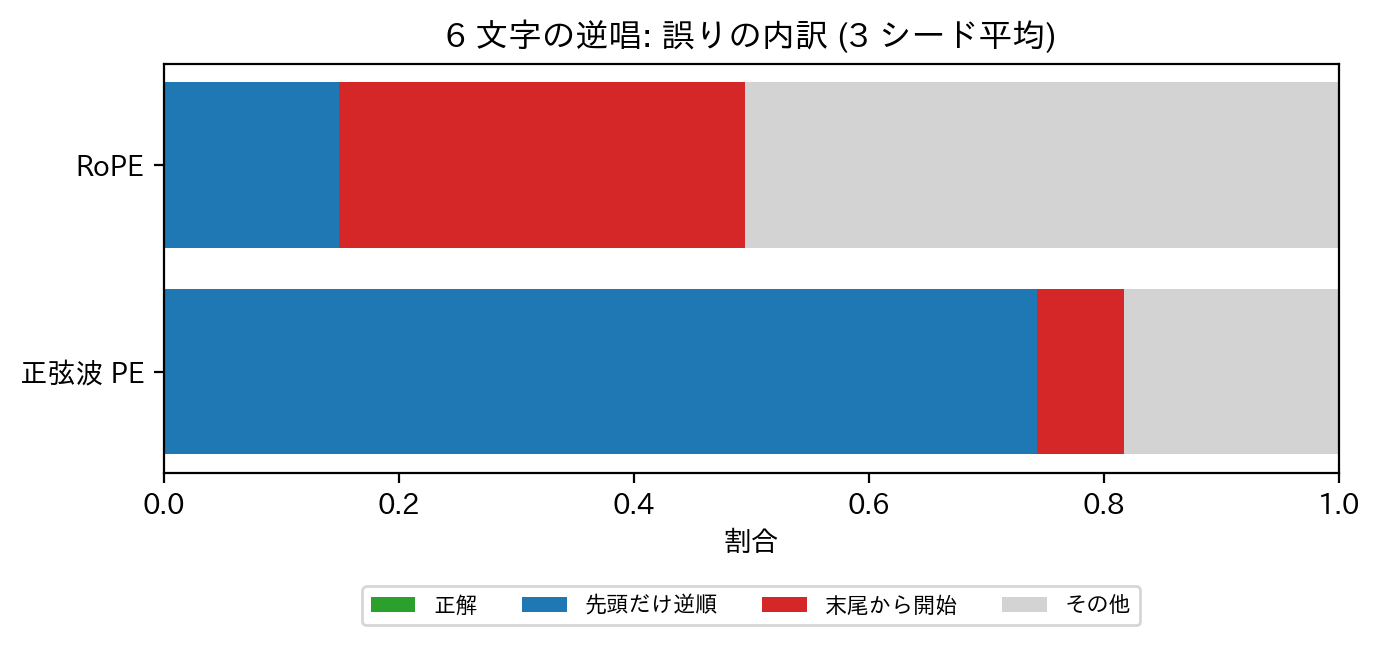

In [8]:
for L in [6, 7]:
    rows = []
    for pe in CONDITIONS:
        T = [tk.reversal_error_types(tests[str(L)], res[(pe, s, L)]['preds'], TRAIN_MAX) for s in SEEDS]
        rows.append([LABELS[pe]] + [f'{np.mean([t[k] for t in T]):.2f}' for k in T[0]])
    show_table(['条件', '正解', '先頭だけ逆順', '末尾から開始', 'その他'], rows, f'{L} 文字の入力に対する誤りの内訳 (3 シード平均)')

fig, ax = plt.subplots(figsize=(7, 3.5))
cats, L = ['正解', '先頭だけ逆順', '末尾から開始', 'その他'], 6
ccol = ['tab:green', 'tab:blue', 'tab:red', 'lightgray']
for i, pe in enumerate(CONDITIONS[1:]):
    T = [tk.reversal_error_types(tests[str(L)], res[(pe, s, L)]['preds'], TRAIN_MAX) for s in SEEDS]
    left = 0
    for c, col in zip(cats, ccol):
        v = np.mean([t[c] for t in T])
        ax.barh(i, v, left=left, color=col, label=c if i == 0 else None)
        left += v
ax.set_yticks([0, 1]); ax.set_yticklabels([LABELS[pe] for pe in CONDITIONS[1:]])
ax.set_xlim(0, 1); ax.set_xlabel('割合'); ax.set_title('6 文字の逆唱: 誤りの内訳 (3 シード平均)')
ax.legend(ncol=4, fontsize=8, loc='upper center', bbox_to_anchor=(0.5, -0.25))
plt.tight_layout(); plt.savefig(f'{FIG_DIR}/rev_error_types.png', dpi=200); plt.show()

## 7. 「どこで止まるか」と「何を出すか」を分ける

学習した長さを超えると，モデルは 5 文字目で `<EOS>` (終わり) を出して止まりやすい。
止まる位置の誤りを取り除くため，**正解の長さまで `<EOS>` を出させない** で生成させる (長さ指定復号)。
これで「どの文字を出すか」だけを比べられる。

In [9]:
rows = []
for pe in CONDITIONS:
    r = [LABELS[pe]]
    for L in [5, 6, 7, 8]:
        v = []
        for s in SEEDS:
            preds = tk.oracle_length_decode(models[(pe, s)], tests[str(L)], vocab, DEVICE)
            v.append(np.mean([pt.char_accuracy(p, t) for p, (_, t) in zip(preds, tests[str(L)])]))
        r.append(f'{np.mean(v):.2f}')
    rows.append(r)
show_table(['条件', '5 文字', '6 文字', '7 文字', '8 文字'], rows, '長さ指定復号での文字一致率 (3 シード平均)')

条件,5 文字,6 文字,7 文字,8 文字
PE なし,0.22,0.20,0.15,0.14
正弦波 PE,1.00,0.25,0.08,0.08
RoPE,1.00,0.57,0.31,0.20


## 8. 解釈

**PE なし**: 学習した長さでも解けない。エンコーダに PE がないと入力は「文字の集まり」にしか見えず (`pe_2x2_shuffle.ipynb`)，
どの文字が最後にあったかがわからないので，逆順に並べようがない。

**正弦波 PE (絶対位置)**: 6 文字の入力に対して「先頭 5 文字の逆順」を出す誤りが多い。
モデルは学習中，「1 文字目に，入力の $n$ 番目 ($n$ = 入力の長さ) を出す」ことを $n = 3, 4, 5$ についてだけ学んだ。
絶対位置で覚えているため，6 番目という見たことのない位置の文字をうまく扱えず，見慣れた 5 番目から始めてしまう，と解釈できる。

**RoPE (相対位置)**: 1 文字目 (入力の最後の文字) は正しく出せることが多い。
「末尾 (`<EOS>` の直前) から数えて何番目か」という相対的な関係は，6 文字の入力でも学習時と同じだからである。
ただし途中で文字を落としたり，5 文字で止まったりする誤りは残る。

**どの PE でも，学習した長さを超えると完全一致率は 0 に近い。** 長さの外挿は Transformer にとって本質的に難しい課題であり，
大規模言語モデルが文脈長を伸ばすときに YaRN などの追加の工夫を必要とするのはこのためである。

## 9. 考えてみよう

1. 正弦波 PE の「先頭だけ逆順」という誤りは，モデルが何を覚えていたことを示しているか。
2. RoPE の 1 文字目が正しいのに，全体としては失敗するのはなぜか。7 節の結果 (長さ指定復号) からわかることは何か。
3. 人間の逆唱課題 (数唱の逆唱など，神経心理学検査で使われる) では，系列が長くなると誤りが増える。人間の誤りの型とモデルの誤りの型を比べるとしたら，何を測ればよいか。
4. 学習に使ったのはランダムな文字列 (非語) である。実在語を逆唱させたら結果は変わると思うか。それはなぜか。